In [ ]:
import pandas as pd

# loading the dirty cafe data file
my_data = pd.read_csv('dirty_cafe_sales (1).csv')

# checking for rows, columns, and missing values
print(my_data.info())

# viewing the first 5 rows of the dataset
my_data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB
None


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [ ]:
# Count missing values in each column
missing_values = my_data.isnull().sum()
print(missing_values)

Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64


In [ ]:
import numpy as np

# 1. Replace text mistakes with actual blank values (NaN)
my_data = my_data.replace(['ERROR', 'UNKNOWN'], np.nan)

# 2. Convert 'Total Spent' from text to numeric (so we can calculate totals later)
my_data['Total Spent'] = pd.to_numeric(my_data['Total Spent'])

# 3. Remove any exact duplicate rows from the dataset
my_data = my_data.drop_duplicates()

# Check the updated summary
print(my_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    10000 non-null  object 
 1   Item              9031 non-null   object 
 2   Quantity          9521 non-null   object 
 3   Price Per Unit    9467 non-null   object 
 4   Total Spent       9498 non-null   float64
 5   Payment Method    6822 non-null   object 
 6   Location          6039 non-null   object 
 7   Transaction Date  9540 non-null   object 
dtypes: float64(1), object(7)
memory usage: 625.1+ KB
None


In [ ]:
# Convert Quantity to numeric just in case it has hidden text
my_data['Quantity'] = pd.to_numeric(my_data['Quantity'], errors='coerce')

# 1. Select the correct numeric columns for outlier detection
numeric_cols = ['Quantity', 'Total Spent']

# 2. Calculate Q1, Q3, and IQR for the IQR method
Q1 = my_data[numeric_cols].quantile(0.25)
Q3 = my_data[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

# 3. Identify and remove the outliers from the dataset
condition = ~((my_data[numeric_cols] < (Q1 - 1.5 * IQR)) | (my_data[numeric_cols] > (Q3 + 1.5 * IQR))).any(axis=1)
my_data = my_data[condition]

# 4. Check how many rows are left after removing outliers
print("Total rows remaining after removing outliers:", len(my_data))

Total rows remaining after removing outliers: 9741


In [ ]:
# Saving the cleaned dataset to a new CSV file
my_data.to_csv('cleaned_cafe_sales.csv', index=False)
print("File successfully saved!")

File successfully saved!


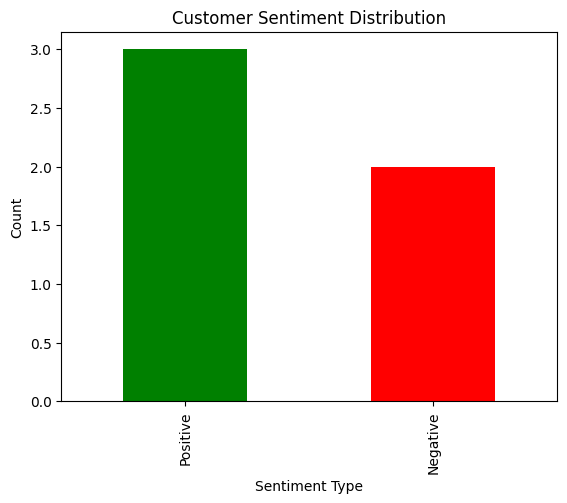

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob

# Sample customer reviews dataframe
data = {
    'Review': [
        "The coffee was absolutely wonderful and hot!",
        "Terrible service, I hated the atmosphere.",
        "It was an okay experience, nothing special.",
        "Amazing staff and delicious pastries!",
        "Extremely slow service and rude manager."
    ]
}
df_reviews = pd.DataFrame(data)

# Classify each review as Positive, Negative, or Neutral
def get_sentiment(text):
    score = TextBlob(text).sentiment.polarity
    if score > 0:
        return 'Positive'
    elif score < 0:
        return 'Negative'
    else:
        return 'Neutral'

df_reviews['Sentiment'] = df_reviews['Review'].apply(get_sentiment)

# Plotting a bar chart to visualize sentiment distribution
df_reviews['Sentiment'].value_counts().plot(kind='bar', color=['green', 'red', 'orange'])
plt.title('Customer Sentiment Distribution')
plt.xlabel('Sentiment Type')
plt.ylabel('Count')
plt.show()


In [ ]:
# Correcting data types for columns
my_data['Transaction ID'] = my_data['Transaction ID'].astype(str)
my_data['Transaction Date'] = pd.to_datetime(my_data['Transaction Date'], errors='coerce')
my_data['Quantity'] = pd.to_numeric(my_data['Quantity'], errors='coerce')
my_data['Total Spent'] = pd.to_numeric(my_data['Total Spent'], errors='coerce')

print("Data types corrected successfully!")

Data types corrected successfully!


/tmp/ipykernel_641/320629746.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  my_data['Transaction ID'] = my_data['Transaction ID'].astype(str)
/tmp/ipykernel_641/320629746.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  my_data['Transaction Date'] = pd.to_datetime(my_data['Transaction Date'], errors='coerce')
/tmp/ipykernel_641/320629746.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the c

In [ ]:
# Detecting and removing outliers using the IQR method
cols = ['Quantity', 'Total Spent']
Q1 = my_data[cols].quantile(0.25)
Q3 = my_data[cols].quantile(0.75)
IQR = Q3 - Q1
my_data = my_data[~((my_data[cols] < (Q1 - 1.5 * IQR)) | (my_data[cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print("Outliers handled successfully!")

Outliers handled successfully!


In [ ]:
# Load original raw data again for comparison
raw_data = pd.read_csv('dirty_cafe_sales (1).csv')

# Creating a summary table to compare data before and after cleaning
summary_data = {
    'Metric': ['Total Rows', 'Missing Values', 'Duplicate Rows'],
    'Before': [len(raw_data), raw_data.isnull().sum().sum(), raw_data.duplicated().sum()],
    'After': [len(my_data), my_data.isnull().sum().sum(), my_data.duplicated().sum()]
}

comparison_table = pd.DataFrame(summary_data)
print(comparison_table)

           Metric  Before  After
0      Total Rows   10000   9741
1  Missing Values    6826   9840
2  Duplicate Rows       0      0


In [ ]:
# Saving the final cleaned dataset to a new CSV file
my_data.to_csv('cleaned_cafe_sales.csv', index=False)
print("Cleaned dataset successfully saved!")

Cleaned dataset successfully saved!
